# Teste 03- Estatística Descritiva
---
Equipe:

 Wanderlânea Maria dos Santos Silva - Matrícula: 2022000412

 Iza Francine Carvalho Vieira - Matrícula: 2024001160


## 1.0 Descrição do problema, dos dados e das variáveis

### O problema

Uma máquina de venda de café registra cada venda realizada. Neste trabalho, usamos esses registros para responder, por meio da estatística descritiva, perguntas simples sobre o funcionamento do negócio:

- Quais cafés são mais vendidos e quais quase não saem?
- Quanto os clientes costumam pagar, e o quanto esse valor varia?
- Como a demanda por cada café se comporta ao longo dos dias?
- O movimento do dia (número de pedidos) tem relação com o preço pago?

tendo também em vista o trabalho com séries temporais.

### Os dados

Foi utilizado o dataset [**Coffee sales**](https://www.kaggle.com/datasets/ihelon/coffee-sales/data), do Kaggle. Cada **linha** da tabela é uma **venda**. O arquivo reúne **3.636 vendas**, registradas de 01/03/2024 a 23/03/2025.

### As variáveis e a natureza de cada uma

- **Qualitativas** descrevem categorias. São **nominais** quando as categorias não têm ordem (por exemplo, o tipo de café) e **ordinais** quando existe uma ordem natural (por exemplo, baixa < média < alta).
- **Quantitativas** são medidas numéricas. São **discretas** quando resultam de contagens (valores inteiros) e **contínuas** quando podem assumir qualquer valor dentro de um intervalo (por exemplo, um preço).

| Variável | O que representa | Natureza | Origem |
|---|---|---|---|
| `date` | Data da venda | Temporal (usada para agrupar as vendas por dia) | Original |
| `datetime` | Data e hora da venda | Temporal | Original |
| `cash_type` | Forma de pagamento | Qualitativa nominal | Original |
| `card` | Identificador anônimo do cartão do cliente | Qualitativa nominal (identificador) | Original |
| `money` | Valor pago na venda | Quantitativa contínua | Original |
| `coffee_name` | Tipo de café vendido (8 tipos) | Qualitativa nominal | Original |
| `order_quantity` | Quantidade de pedidos feitos no dia da venda | Quantitativa discreta | **Criada** |
| `coffee_quantity` | Quantidade de pedidos daquele mesmo café no dia | Quantitativa discreta | **Criada** |
| `coffee_demand` | Nível de demanda do café no dia (`low` < `medium` < `high`) | Qualitativa ordinal | **Criada** |


In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

### Carregamento dos dados

Lemos o arquivo CSV com o `pandas`. O resultado é uma tabela (`DataFrame`) chamada `data`, em que cada linha é uma venda.

In [ ]:
data = pd.read_csv("/content/coffee_sales.csv")
display(data)

,date,datetime,cash_type,card,money,coffee_name,order_quantity,coffee_quantity,coffee_demand,monthly_sales
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.70,Latte,11,2,low,7050.20
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.70,Hot Chocolate,11,3,medium,7050.20
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.70,Hot Chocolate,11,3,medium,7050.20
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.90,Americano,11,1,low,7050.20
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.70,Latte,11,2,low,7050.20
...,...,...,...,...,...,...,...,...,...,...
3631,2025-03-23,2025-03-23 10:34:54.894,card,ANON-0000-0000-1158,35.76,Cappuccino,6,1,low,9986.44
3632,2025-03-23,2025-03-23 14:43:37.362,card,ANON-0000-0000-1315,35.76,Cocoa,6,2,high,9986.44
3633,2025-03-23,2025-03-23 14:44:16.864,card,ANON-0000-0000-1315,35.76,Cocoa,6,2,high,9986.44
3634,2025-03-23,2025-03-23 15:47:28.723,card,ANON-0000-0000-1316,25.96,Americano,6,1,low,9986.44


### Construção das variáveis quantitativa (discreta) e qualitativa (ordinal)
Foram criadas três colunas novas:

- **`order_quantity` (discreta):** total de pedidos feitos no dia da venda.
- **`coffee_quantity` (discreta):** total de pedidos daquele mesmo café no mesmo dia.
- **`coffee_demand` (ordinal):** nível de demanda do café naquele dia, comparando-o com os demais cafés do dia:
  - `high` (alta): o café foi o mais vendido do dia;
  - `medium` (média): o café vendeu mais que a média do dia, mas não foi o mais vendido;
  - `low` (baixa): nos demais casos.


In [ ]:
# Converte 'date' de texto para data, para podermos agrupar as vendas por dia
data["date"] = pd.to_datetime(data["date"])

# order_quantity: para cada venda, conta quantos pedidos houve no mesmo dia (variável discreta)
data['order_quantity'] = (data.groupby('date')['coffee_name'].transform("count")) # quantidade de pedidos feitos no dia

# coffee_quantity: conta quantos pedidos do mesmo café houve no mesmo dia (variável discreta)
data['coffee_quantity'] = (data.groupby(['date', 'coffee_name']))['coffee_name'].transform('count') # quantidade de pedidos feitos no dia dos cafés

# Valores de referência de cada dia para classificar a demanda
max_quantity = (data.groupby('date')['coffee_quantity'].transform('max')) # Maior quantidade de pedidos no dia

mean_quantity = (data.groupby('date')['coffee_quantity'].transform('mean')) # A média da quantidade de pedidos no dia

# Regra da demanda: todos começam como 'low' (baixa)
data['coffee_demand'] = 'low'

# 'medium' quando o café vendeu mais que a média do dia
data.loc[data['coffee_quantity'] > mean_quantity, 'coffee_demand'] = 'medium'

# 'high' quando o café foi o mais vendido do dia (vem por último e prevalece sobre 'medium')
data.loc[data['coffee_quantity'] == max_quantity, 'coffee_demand'] = 'high'

# Declara a ordem das categorias, tornando a variável ordinal
category_order = ['low', 'medium', 'high'] #low < medium < high

data['coffee_demand'] = pd.Categorical(data['coffee_demand'], categories=category_order, ordered=True)

data['date'] = pd.to_datetime(data['date'])

data['monthly_sales'] = data.groupby(data['date'].dt.to_period('M'))['money'].transform('sum')

data.to_csv("coffee_sales.csv", index=False)

display(data)

,date,datetime,cash_type,card,money,coffee_name,order_quantity,coffee_quantity,coffee_demand,monthly_sales
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.70,Latte,11,2,low,7050.20
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.70,Hot Chocolate,11,3,medium,7050.20
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.70,Hot Chocolate,11,3,medium,7050.20
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.90,Americano,11,1,low,7050.20
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.70,Latte,11,2,low,7050.20
...,...,...,...,...,...,...,...,...,...,...
3631,2025-03-23,2025-03-23 10:34:54.894,card,ANON-0000-0000-1158,35.76,Cappuccino,6,1,low,9986.44
3632,2025-03-23,2025-03-23 14:43:37.362,card,ANON-0000-0000-1315,35.76,Cocoa,6,2,high,9986.44
3633,2025-03-23,2025-03-23 14:44:16.864,card,ANON-0000-0000-1315,35.76,Cocoa,6,2,high,9986.44
3634,2025-03-23,2025-03-23 15:47:28.723,card,ANON-0000-0000-1316,25.96,Americano,6,1,low,9986.44


### Estrutura dos dados

Antes de analisar, conferimos a estrutura da tabela.

In [ ]:
data.columns

Index(['date', 'datetime', 'cash_type', 'card', 'money', 'coffee_name',
       'order_quantity', 'coffee_quantity', 'coffee_demand', 'monthly_sales'],
      dtype='object')

In [ ]:
data.isna()

,date,datetime,cash_type,card,money,coffee_name,order_quantity,coffee_quantity,coffee_demand,monthly_sales
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
3631,False,False,False,False,False,False,False,False,False,False
3632,False,False,False,False,False,False,False,False,False,False
3633,False,False,False,False,False,False,False,False,False,False
3634,False,False,False,False,False,False,False,False,False,False


In [ ]:
data.isna().sum()

,0
date,0
datetime,0
cash_type,0
card,89
money,0
coffee_name,0
order_quantity,0
coffee_quantity,0
coffee_demand,0
monthly_sales,0


In [ ]:
data.dtypes

,0
date,datetime64[ns]
datetime,object
cash_type,object
card,object
money,float64
coffee_name,object
order_quantity,int64
coffee_quantity,int64
coffee_demand,category
monthly_sales,float64


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3636 entries, 0 to 3635
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             3636 non-null   datetime64[ns]
 1   datetime         3636 non-null   object        
 2   cash_type        3636 non-null   object        
 3   card             3547 non-null   object        
 4   money            3636 non-null   float64       
 5   coffee_name      3636 non-null   object        
 6   order_quantity   3636 non-null   int64         
 7   coffee_quantity  3636 non-null   int64         
 8   coffee_demand    3636 non-null   category      
 9   monthly_sales    3636 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 259.5+ KB


**Interpretação.** O conjunto de dados tem 3.636 vendas e 9 colunas: 6 originais e as 3 variáveis criadas (`order_quantity`, `coffee_quantity` e `coffee_demand`). Apenas a coluna `card` tem valores ausentes: 89 de 3.636 vendas. Como `card` é só um identificador anônimo e não entra nas análises, não foi necessário remover linhas nem preencher valores.

Os tipos de dado conferem com a natureza de cada variável. `money` é decimal (`float64`), o que combina com uma variável contínua. `order_quantity` e `coffee_quantity` são inteiros (`int64`), como convém a contagens (discretas). `coffee_demand` é categórica (`category`) com ordem definida, isto é, ordinal. `coffee_name` e `cash_type` são texto (`object`), categorias nominais.

## 1.1 Análise univariada

A análise univariada estuda **uma variável por vez**. A ferramenta usada aqui é a **distribuição de frequências**, uma tabela que mostra quantas vezes cada valor (ou faixa de valores) aparece nos dados. Em cada tabela, aparecem:

- **frequência absoluta**
- **frequência relativa**
- **porcentagem**

Analisamos duas variáveis qualitativas (`coffee_name`, nominal, e `coffee_demand`, ordinal) e uma quantitativa (`money`, contínua, agrupada em faixas).

### Qualitativa nominal — `coffee_name`

Como a variável é nominal, listamos as categorias (os tipos de café) e contamos as vendas de cada uma. Primeiro exploramos a variável; depois, calculamos as frequências.

In [ ]:
data.coffee_name

,coffee_name
0,Latte
1,Hot Chocolate
2,Hot Chocolate
3,Americano
4,Latte
...,...
3631,Cappuccino
3632,Cocoa
3633,Cocoa
3634,Americano


In [ ]:
type(data['coffee_name'])

pandas.core.series.Series

In [ ]:
data['coffee_name'].unique()

array(['Latte', 'Hot Chocolate', 'Americano', 'Americano with Milk',
       'Cocoa', 'Cortado', 'Espresso', 'Cappuccino'], dtype=object)

In [ ]:
data['coffee_name'].nunique()

8

In [ ]:
data['coffee_name'].value_counts()

,count
coffee_name,
Americano with Milk,824
Latte,782
Americano,578
Cappuccino,501
Cortado,292
Hot Chocolate,282
Cocoa,243
Espresso,134


In [ ]:
data['coffee_name'].value_counts(normalize=True)

,proportion
coffee_name,
Americano with Milk,0.226623
Latte,0.215072
Americano,0.158966
Cappuccino,0.137789
Cortado,0.080308
Hot Chocolate,0.077558
Cocoa,0.066832
Espresso,0.036854


In [ ]:
type(data['coffee_name'])

pandas.core.series.Series

**Interpretação.** Os 8 tipos de café são vendidos em quantidades bem diferentes. O *Americano with Milk* é o mais vendido (824 vendas, 22,7%), seguido de perto pelo *Latte* (782 vendas, 21,5%). Juntos, os dois respondem por 44,2% das vendas. Somando o *Americano* (15,9%) e o *Cappuccino* (13,8%), quatro cafés concentram 73,8% de tudo o que é vendido. No outro extremo, *Cortado*, *Hot Chocolate*, *Cocoa* e *Espresso* têm de 3,7% a 8,0% das vendas cada, e o *Espresso* é o menos vendido (134 vendas, 3,7%).

### Qualitativa ordinal — `coffee_demand`

Como a variável é ordinal, as categorias têm ordem (`low` < `medium` < `high`). Por isso, além das frequências, faz sentido calcular a **porcentagem acumulada** seguindo essa ordem.

In [ ]:
display(data['coffee_demand'])
display(pd.DataFrame(data['coffee_demand'].value_counts(sort=False)))

,coffee_demand
0,low
1,medium
2,medium
3,low
4,low
...,...
3631,low
3632,high
3633,high
3634,low


,count
coffee_demand,
low,1659
medium,200
high,1777


In [ ]:
list(data['coffee_demand'].unique())

['low', 'medium', 'high']

**Interpretação.** Em 48,9% das vendas (1.777), o café vendido foi o campeão de vendas do dia (demanda alta), e em 45,6% (1.659) o café ficou abaixo da média do dia (demanda baixa). A demanda média é rara: apenas 200 vendas (5,5%).

### Quantitativa contínua — `money`

Como `money` é contínua e assume muitos valores, as vendas são agrupadas em **faixas (classes)**.

,count
"(18.096999999999998, 18.485]",36
"(18.485, 18.849]",0
"(18.849, 19.214]",0
"(19.214, 19.579]",0
"(19.579, 19.943]",0
"(19.943, 20.308]",0
"(20.308, 20.673]",0
"(20.673, 21.037]",0
"(21.037, 21.402]",59
"(21.402, 21.767]",0


Text(0, 0.5, 'frequência')

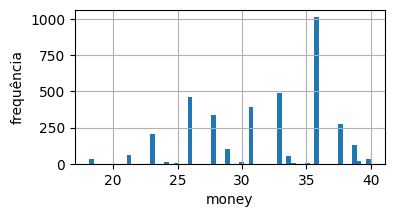

In [ ]:
x = data['money']
n = len(x)
k = round(np.sqrt(n))
df_money = x.value_counts(bins=k, sort=False)
display(pd.DataFrame(df_money))

histograma = data['money'].hist(figsize=(4,2), bins=k);
histograma.set_xlabel('money')
histograma.set_ylabel('frequência')

## 1.2 Gráficos univariados

Os gráficos mostram a mesma informação das tabelas de forma visual. O tipo de gráfico depende da natureza da variável:

- **qualitativa ordinal** (`coffee_demand`): gráfico de barras, respeitando a ordem das categorias;
- **qualitativa nominal** (`coffee_name`): gráfico de barras, uma barra por categoria;
- **quantitativa contínua** (`money`): histograma e boxplot.
- **quantitativa discreta** (`order_quantity`): gráfico de barras, uma barra para cada valor inteiro;


### Qualitativa ordinal — coffee_demand


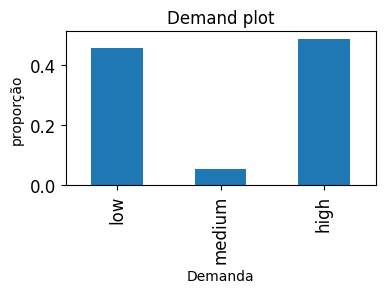

In [ ]:
df_demand = data['coffee_demand'].value_counts(normalize=True, sort=False)
demand_plot = df_demand.plot(kind='bar', figsize=(4,2), title='Demand plot',fontsize=12);

demand_plot.set_xlabel('Demanda');
demand_plot.set_ylabel('proporção');

**Interpretação.** O gráfico tem formato "em U": duas barras altas e quase iguais (demanda alta, 48,9%, e demanda baixa, 45,6%) e uma barra pequena no meio (demanda média, 5,5%). Em outras palavras, um café costuma ou ser o campeão de vendas do dia ou ficar abaixo da média; ficar no meio-termo é raro.

### Qualitativa nominal — `coffee_name`

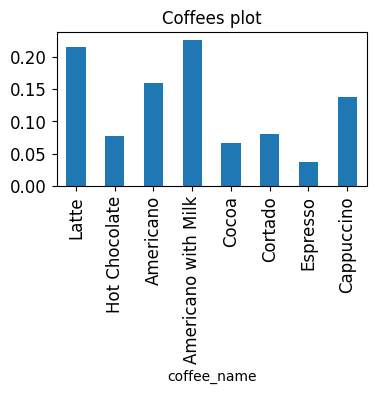

In [ ]:
df_coffees = data['coffee_name'].value_counts(normalize=True, sort=False)
coffees_plot = df_coffees.plot(kind='bar', figsize=(4,2), title='Coffees plot',fontsize=12);

**Interpretação.** O gráfico de barras, ordenado do mais para o menos vendido, mostra o mesmo padrão da tabela: duas barras mais altas (*Americano with Milk* e *Latte*, ambos acima de 21% das vendas), um grupo intermediário (*Americano*, com 15,9%, e *Cappuccino*, com 13,8%) e quatro barras baixas (*Cortado*, *Hot Chocolate*, *Cocoa* e *Espresso*, todos abaixo de 8,1%).

### Quantitativa contínua — `money`

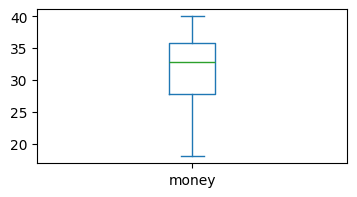

In [ ]:
box_plot = data['money'].plot(kind='box', figsize=(4,2), title='')

**Interpretação.** O boxplot realiza a seguinte distribuição: a caixa vai de 27,92 (Q1) a 35,76 (Q3), e a mediana (32,82) fica mais perto do limite superior da caixa do que do inferior, o que indica assimetria à esquerda, com cauda em direção aos preços baixos.

### Quantitativa discreta — `order_quantity`

Cada barra mostra a proporção de vendas que aconteceram em dias com aquele número de pedidos.

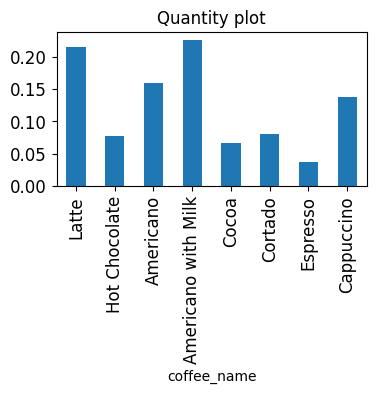

In [ ]:
df_quantity = data['order_quantity'].value_counts(normalize=True, sort=False)
quantity_plot = df_coffees.plot(kind='bar', figsize=(4,2), title='Quantity plot',fontsize=12);

**Interpretação.** O número de pedidos por dia vai de 1 a 26, e a maior parte das vendas se concentra no meio dessa faixa: 44% delas acontecem em dias com 8 a 13 pedidos. Os valores mais frequentes são 11 pedidos (8,2% das vendas) e 8 pedidos (8,1%). Dias muito fracos, com até 3 pedidos, são raros (1,8% das vendas), e dias muito cheios, com 22 pedidos ou mais, reúnem 7,7%.

## 1.3 Análise bivariada

A análise bivariada estuda **duas variáveis ao mesmo tempo**, para verificar se existe **associação** entre elas, om distribuição de frequências conjunta e figuras. A ferramenta depende da natureza do par de variáveis:

### Qualitativa × qualitativa — `coffee_name` × `coffee_demand`

Uma **tabela cruzada** conta as vendas em cada combinação de café e nível de demanda. Começamos pela distribuição de frequências conjunta (em número de vendas) e depois passamos para proporções.

Na tabela abaixo, cada **coluna** soma 1: ela mostra, dentro de cada nível de demanda, qual é a participação de cada café.

In [ ]:
pd.crosstab(index=data['coffee_name'], columns=data['coffee_demand'],margins=True, margins_name='Total', normalize='columns')

coffee_demand,low,medium,high,Total
coffee_name,,,,
Americano,0.133213,0.110,0.188520,0.158966
Americano with Milk,0.155515,0.275,0.287563,0.226623
Cappuccino,0.167571,0.170,0.106359,0.137789
Cocoa,0.097649,0.040,0.041080,0.066832
Cortado,0.109705,0.050,0.056275,0.080308
Espresso,0.069922,0.015,0.008441,0.036854
Hot Chocolate,0.103074,0.125,0.048396,0.077558
Latte,0.163351,0.215,0.263365,0.215072


Agora, o ponto de vista inverso: dentro de cada **café**, qual a proporção de vendas em cada nível de demanda (cada linha soma 1). O gráfico de barras empilhadas é a figura bivariada desta seção.

******** Conditional Proportion: coffee_demand per coffee_name ********


coffee_demand,low,medium,high
coffee_name,,,
Americano,0.382353,0.038062,0.579585
Americano with Milk,0.313107,0.066748,0.620146
Cappuccino,0.554890,0.067864,0.377246
Cocoa,0.666667,0.032922,0.300412
Cortado,0.623288,0.034247,0.342466
Espresso,0.865672,0.022388,0.111940
Hot Chocolate,0.606383,0.088652,0.304965
Latte,0.346547,0.054987,0.598465


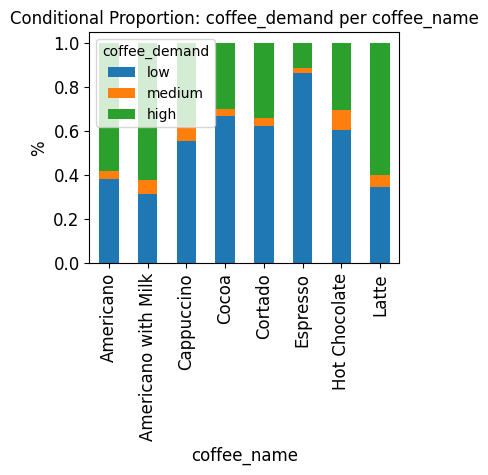

In [ ]:
variavel_1 = 'coffee_name'
variavel_2 = 'coffee_demand'

def quali_quali_association(variavel_1, variavel_2, stacked):
  table = pd.crosstab(index=data['coffee_name'], columns=data['coffee_demand'], normalize='index')
  title = "Conditional Proportion: " + variavel_2 + " per " + variavel_1
  print("******** " + title + " ********")
  display(table)
  image = table.plot(kind='bar', figsize=(4,3), stacked=stacked, title=title, fontsize=12)
  image.set_ylabel("%",fontsize=12)
  image.set_xlabel(variavel_1,fontsize=12)

quali_quali_association(variavel_1='coffee_name', variavel_2='coffee_demand', stacked=True)

In [ ]:
data[['coffee_name', 'coffee_demand']]

,coffee_name,coffee_demand
0,Latte,low
1,Hot Chocolate,medium
2,Hot Chocolate,medium
3,Americano,low
4,Latte,low
...,...,...
3631,Cappuccino,low
3632,Cocoa,high
3633,Cocoa,high
3634,Americano,low


**Interpretação.** Existe associação entre o tipo de café e o nível de demanda. Olhando por café (tabela e gráfico de barras), o *Espresso* é o caso mais extremo: 86,6% das suas vendas ocorrem em demanda baixa e só 11,2% em demanda alta, ou seja, quase nunca é o campeão do dia. *Cocoa* (66,7%), *Cortado* (62,3%), *Hot Chocolate* (60,6%) e *Cappuccino* (55,5%) também ficam principalmente em demanda baixa. Já *Americano with Milk* (62,0%), *Latte* (59,8%) e *Americano* (58,0%) estão em demanda alta na maior parte das vendas. A demanda média é pouco frequente em qualquer café (de 2,2% a 8,9%).

A tabela por colunas mostra o mesmo resultado por outro ângulo: entre as vendas de demanda alta, três cafés (*Americano with Milk*, 28,8%, *Latte*, 26,3%, e *Americano*, 18,9%) somam 73,9%, enquanto o *Espresso* representa apenas 0,8%.

### Quantitativa × qualitativa — `money` × `coffee_name`

Para comparar o preço entre os tipos de café, resumimos `money` em cada café (quantidade, média, desvio padrão, mínimo, quartis e máximo) e desenhamos um boxplot para cada um.

******** money per coffee_name ********


money                                                   \
                     count       mean       std    min    25%    50%    75%   
coffee_name                                                                   
Americano            578.0  26.059273  1.740508  23.02  25.96  25.96  25.96   
Americano with Milk  824.0  30.666408  1.940697  27.92  27.92  30.86  32.82   
Cappuccino           501.0  35.996287  1.906202  32.82  35.76  35.76  37.72   
Cocoa                243.0  35.712593  1.307759  32.82  35.76  35.76  35.76   
Cortado              292.0  25.804315  2.148458  23.02  23.02  25.96  27.92   
Espresso             134.0  21.002090  2.078350  18.12  18.12  21.06  23.02   
Hot Chocolate        282.0  36.072553  1.527680  32.82  35.76  35.76  35.76   
Latte                782.0  35.634655  1.936673  32.82  35.76  35.76  35.76   

                           
                      max  
coffee_name                
Americano            30.0  
Americano with Milk  35.0  
Cappuccino           40.0  
Cocoa                40.0  
Cortado              30.0  
Espresso             25.0  
Hot Chocolate        40.0  
Latte                40.0

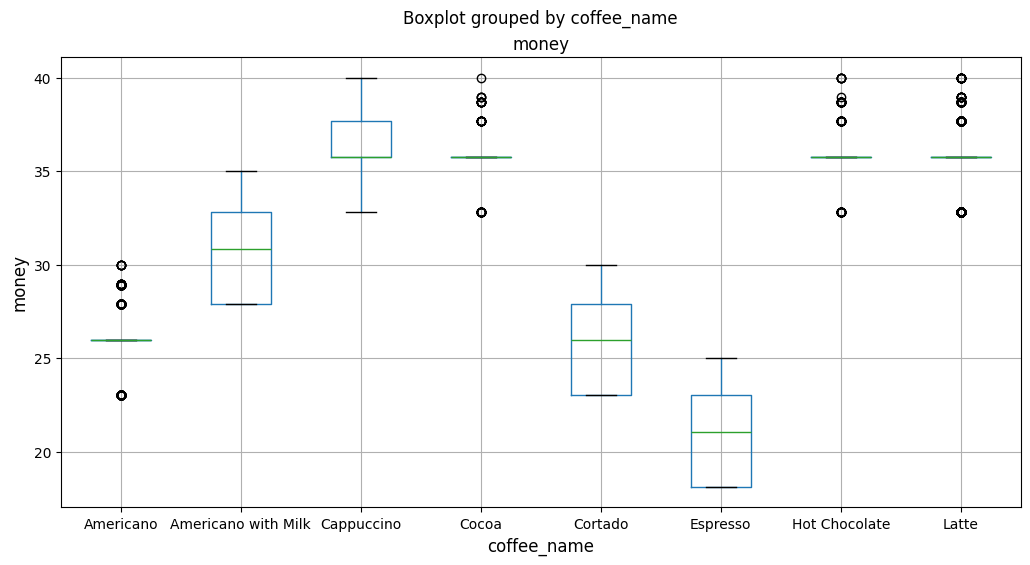

In [ ]:
quanti = 'money'
quali = 'coffee_name'

def quali_quanti_association(quanti, quali, vert):
  title = quanti+ " per " + quali
  print("******** " + title + " ********")
  display(data[[quanti, quali]].groupby(quali).describe())
  box = data.boxplot(column=quanti,figsize=(12,6), vert=vert, by=quali);
  box.set_ylabel(quanti,fontsize=12);
  box.set_xlabel(quali,fontsize=12);

quali_quanti_association(quanti='money', quali='coffee_name', vert=True)

**Interpretação.** O preço depende bastante do tipo de café. O *Espresso* é o mais barato (média de 21,00), seguido de *Cortado* e *Americano* (cerca de 26) e do *Americano with Milk* (cerca de 30,67). O grupo mais caro reúne *Cappuccino*, *Cocoa*, *Hot Chocolate* e *Latte*, todos com média entre 35,6 e 36,1. Nos boxplots, as caixas dos cafés baratos e dos caros pouco se sobrepõem. Dentro de cada café, a variação é pequena (desvios padrão entre 1,3 e 2,1), o que sugere preços de tabela com poucos reajustes.

### Quantitativa × quantitativa — `money` × `order_quantity`

Para medir a relação entre duas variáveis quantitativas, usamos o **coeficiente de correlação de Pearson**. A visualização é feita com um **diagrama de dispersão**, em que cada ponto é uma venda.

******** money per order_quantity ********


money                                                         
                count       mean       std    min     25%    50%    75%    max
order_quantity                                                                
1                 8.0  31.717500  5.529778  23.02  27.430  32.82  36.25  37.72
2                22.0  31.919091  5.621721  21.06  28.165  32.82  35.76  40.00
3                36.0  32.687778  5.311009  18.12  28.655  34.29  36.25  40.00
4               104.0  32.313846  4.789441  21.06  28.655  32.82  35.76  40.00
5               135.0  32.364889  5.161921  18.12  27.920  32.82  37.72  40.00
6               216.0  32.161944  5.488371  18.12  27.920  32.82  36.25  40.00
7               203.0  32.238719  4.843463  21.06  27.920  33.80  35.76  40.00
8               296.0  32.164189  4.858051  18.12  27.920  32.82  35.76  40.00
9               252.0  32.445714  4.828845  18.12  27.920  35.76  35.76  39.00
10              270.0  31.244296  4.987719  18.12  27.920  32.82  35.76  40.00
11              297.0  32.467003  4.692689  18.12  27.920  32.82  35.76  40.00
12              252.0  31.013333  5.065642  18.12  27.920  30.86  35.76  40.00
13              234.0  30.419402  4.981372  18.12  27.920  30.86  35.57  40.00
14              140.0  32.800143  4.321654  21.06  30.860  32.82  35.76  40.00
15              180.0  31.840000  4.752702  18.12  27.920  32.82  35.76  37.72
16              176.0  31.635682  4.804273  18.12  27.920  32.82  35.76  39.00
17              170.0  31.915529  4.305107  18.12  27.920  32.82  35.76  37.72
18              126.0  32.143333  4.477155  21.06  27.185  35.76  35.76  35.76
19               76.0  31.569211  5.041936  21.06  25.960  35.76  35.76  35.76
20              100.0  31.301000  4.829959  21.06  25.960  30.86  35.76  35.76
21               63.0  31.948889  4.693685  21.06  25.960  35.76  35.76  35.76
22               88.0  30.392273  5.270088  18.12  25.960  32.82  35.76  35.76
23               69.0  29.880000  4.853663  18.12  25.960  27.92  35.76  35.76
24               72.0  29.036111  4.713725  18.12  25.960  27.92  32.82  35.76
25               25.0  31.840000  4.473068  21.06  30.860  30.86  35.76  35.76
26               26.0  32.179231  4.284672  25.96  27.185  35.76  35.76  35.76

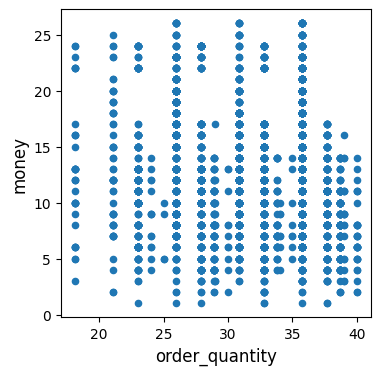

In [ ]:
quanti_1 = 'money'
quanti_2 = 'order_quantity'

def quanti_quanti_association(quanti_1, quanti_2):
    title = quanti_1 + " per " + quanti_2
    print("******** " + title + " ********")
    display(data[[quanti_1, quanti_2]].groupby(quanti_2).describe())
    boxVarS = data.plot.scatter(x=quanti_1,y=quanti_2, figsize=(4,4));
    boxVarS.set_ylabel(quanti_1,fontsize=12);
    boxVarS.set_xlabel(quanti_2,fontsize=12);

quanti_quanti_association('money', 'order_quantity')

**Interpretação.** A correlação é de aproximadamente -0,08, praticamente zero. Isso indica que **não há relação linear relevante** entre o preço pago e o movimento do dia: dias com muitos ou com poucos pedidos têm preços parecidos.  No diagrama de dispersão, os pontos formam colunas verticais (uma por valor de `order_quantity`, que é discreta) e faixas horizontais (os preços fixos de tabela), sem inclinação aparente.

## 1.4 Medidas de posição (tendência central)

As medidas de posição indicam **onde os valores se concentram**, isto é, o valor "típico" da variável:

- **média:** soma de todos os valores dividida pela quantidade de valores; é sensível a valores extremos (outlier);
- **mediana:** valor do meio quando os dados estão ordenados (metade dos dados fica abaixo e metade acima);
- **moda:** valor mais frequente; também serve para variáveis qualitativas.


### Resumo geral (`describe`)

O método `describe()` calcula várias medidas de uma vez. Para variáveis qualitativas, ele informa a quantidade de valores (`count`), o número de categorias (`unique`), a categoria mais frequente (`top`, que é a moda) e sua frequência (`freq`). Para variáveis quantitativas, informa média, desvio padrão, mínimo, quartis e máximo.

In [ ]:
quali_describe = data[['coffee_name', 'coffee_demand']].describe()
display(quali_describe)

,coffee_name,coffee_demand
count,3636,3636
unique,8,3
top,Americano with Milk,high
freq,824,1777


In [ ]:
quanti_describe = data[['money', 'order_quantity']].describe()
display(quanti_describe)

,money,order_quantity
count,3636.000000,3636.000000
mean,31.746859,12.263476
std,4.919926,5.410662
min,18.120000,1.000000
25%,27.920000,8.000000
50%,32.820000,11.000000
75%,35.760000,16.000000
max,40.000000,26.000000


**Interpretação.** Entre as variáveis qualitativas, `coffee_name` tem 8 categorias e a mais frequente (a moda) é o *Americano with Milk*, com 824 vendas; `coffee_demand` tem 3 categorias e a moda é `high`, com 1.777 vendas. Entre as quantitativas, o preço tem média de 31,75 e mediana de 32,82. Os quartis mostram que 25% das vendas custam até 27,92 e que 75% custam até 35,76, de modo que a metade central das vendas está entre esses dois valores. Já `order_quantity` tem média de 12,26 e mediana de 11, e 75% das vendas acontecem em dias com até 16 pedidos.

In [ ]:
n = len(data['money'])
erro = data['money'] - quanti_describe.loc['mean','money']
erro_modulo = erro.abs()
media_erro_modulo = erro_modulo.mean()
display(pd.DataFrame({'Money': data['money'],
                      'média':  quanti_describe.loc['mean','money'],
                      'erro': erro,
                     '|erro|':erro_modulo}))

,Money,média,erro,|erro|
0,38.70,31.746859,6.953141,6.953141
1,38.70,31.746859,6.953141,6.953141
2,38.70,31.746859,6.953141,6.953141
3,28.90,31.746859,-2.846859,2.846859
4,38.70,31.746859,6.953141,6.953141
...,...,...,...,...
3631,35.76,31.746859,4.013141,4.013141
3632,35.76,31.746859,4.013141,4.013141
3633,35.76,31.746859,4.013141,4.013141
3634,25.96,31.746859,-5.786859,5.786859


Média:   31.75
Mediana: 32.82
Moda:    35.76


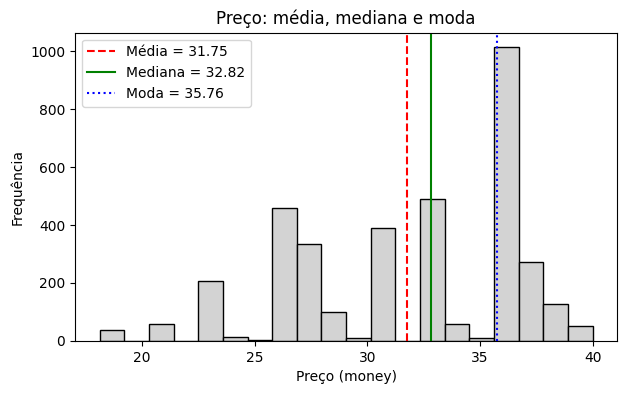

In [ ]:
mean = data['money'].mean()
median = data['money'].median()
mode = data['money'].mode()[0]

print(f"Média:   {mean:.2f}")
print(f"Mediana: {median:.2f}")
print(f"Moda:    {mode:.2f}")

plt.figure(figsize=(7, 4))
plt.hist(data['money'], bins=20, color='lightgray', edgecolor='black')
plt.axvline(mean, color='red', linestyle='--', label=f'Média = {mean:.2f}')
plt.axvline(median, color='green', linestyle='-', label=f'Mediana = {median:.2f}')
plt.axvline(mode, color='blue', linestyle=':', label=f'Moda = {mode:.2f}')
plt.title('Preço: média, mediana e moda')
plt.xlabel('Preço (money)')
plt.ylabel('Frequência')
plt.legend()
plt.show()

**Interpretação.** O preço tem média de 31,75, mediana de 32,82 e moda de 35,76. Como **média < mediana < moda**, a distribuição é assimétrica à esquerda: o preço mais comum (35,76) é alto, e as vendas de cafés baratos (*Espresso*, *Cortado* e *Americano*) puxam a média para baixo. No gráfico, a linha vermelha (média) fica à esquerda da verde (mediana), e a azul (moda) fica à direita das duas.

### Quantidade de pedidos no dia (`order_quantity`) — quantitativa discreta

In [ ]:
print(f"Média:   {data['order_quantity'].mean():.2f}")
print(f"Mediana: {data['order_quantity'].median():.0f}")
print(f"Moda:    {data['order_quantity'].mode()[0]}")

Média:   12.26
Mediana: 11
Moda:    11


**Interpretação.** Em um dia típico há cerca de 11 pedidos (a mediana e a moda são iguais a 11). A média é um pouco maior, 12,26, porque existem dias muito movimentados, com até 26 pedidos, que a puxam para cima.

### Tipo de café e demanda — qualitativas - moda



In [ ]:
print("Moda de coffee_name:  ", data['coffee_name'].mode()[0])
print("Moda de coffee_demand:", data['coffee_demand'].mode()[0])

Moda de coffee_name:   Americano with Milk
Moda de coffee_demand: high


**Interpretação.** O café mais vendido é o *Americano with Milk* (824 vendas, cerca de 22,7% do total), seguido de perto pelo *Latte*. A demanda mais frequente é a **alta** (1.777 vendas), mas a demanda baixa (1.659 vendas) aparece quase tanto.

## 1.5 Medidas de dispersão

As medidas de dispersão mostram **o quanto os valores se espalham** em torno do centro. Usamos:

- **amplitude:** diferença entre o maior e o menor valor;
- **variância** e **desvio padrão:** medem o afastamento médio dos valores em relação à média (o desvio padrão é a raiz da variância e tem a mesma unidade dos dados);
- **coeficiente de variação (CV):** desvio padrão dividido pela média, em porcentagem;
- **intervalo interquartil (IQR):** Q3 - Q1, a amplitude da metade central dos dados;
- **IQV (índice de variação qualitativa):** a medida de dispersão para variáveis qualitativas.

### Preço (`money`)

In [ ]:
minimo = data['money'].min()
maximo = data['money'].max()
amplitude = maximo - minimo
variancia = data['money'].var()
desvio = data['money'].std()
media = data['money'].mean()
cv = desvio / media * 100
q1 = data['money'].quantile(0.25)
q3 = data['money'].quantile(0.75)
iiq = q3 - q1

print(f"Mínimo: {minimo:.2f}   Máximo: {maximo:.2f}   Amplitude: {amplitude:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Desvio padrão: {desvio:.2f}")
print(f"Coeficiente de variação: {cv:.1f}%")
print(f"Q1: {q1:.2f}   Q3: {q3:.2f}   IQR: {iiq:.2f}")

Mínimo: 18.12   Máximo: 40.00   Amplitude: 21.88
Variância: 24.21
Desvio padrão: 4.92
Coeficiente de variação: 15.5%
Q1: 27.92   Q3: 35.76   IQR: 7.84


**Interpretação.** Os preços vão de 18,12 a 40,00, uma amplitude de 21,88. O desvio padrão é 4,92 (variância de 24,21), o que dá um coeficiente de variação de 15,5%, uma dispersão **moderada**. O IQR é 7,84: a metade central das vendas tem preços entre 27,92 e 35,76. O desvio médio absoluto, de cerca de 4,2, é menor que o desvio padrão (4,92), o que é esperado, já que o desvio padrão eleva os afastamentos ao quadrado e dá mais peso aos valores mais distantes da média.

Dispersão do preço dentro de cada tipo de café:

In [ ]:
dispersao = data.groupby('coffee_name')['money'].agg(['mean', 'std'])
dispersao['cv (%)'] = dispersao['std'] / dispersao['mean'] * 100
display(dispersao.round(2))

,mean,std,cv (%)
coffee_name,,,
Americano,26.06,1.74,6.68
Americano with Milk,30.67,1.94,6.33
Cappuccino,36.00,1.91,5.30
Cocoa,35.71,1.31,3.66
Cortado,25.80,2.15,8.33
Espresso,21.00,2.08,9.90
Hot Chocolate,36.07,1.53,4.24
Latte,35.63,1.94,5.43


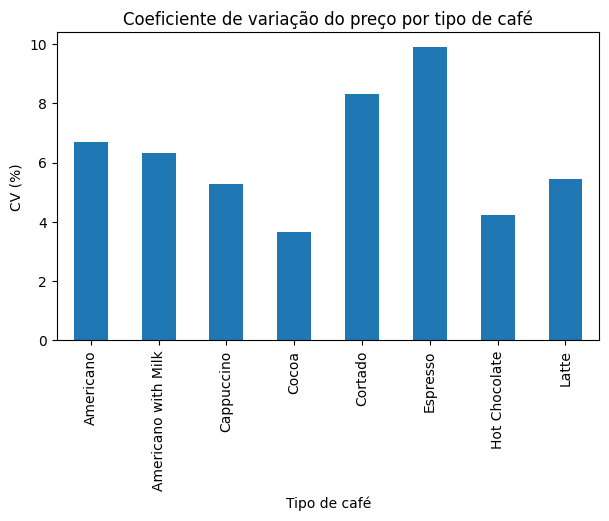

In [ ]:
dispersao['cv (%)'].plot(kind='bar', figsize=(7, 4), title='Coeficiente de variação do preço por tipo de café')
plt.xlabel('Tipo de café')
plt.ylabel('CV (%)')
plt.show()

**Interpretação.** Dentro de cada café, a dispersão do preço é bem menor que a dispersão geral: o CV varia de 3,7% (*Cocoa*) a 9,9% (*Espresso*), sempre abaixo dos 15,5% do conjunto.

### Quantidade de pedidos no dia (`order_quantity`)

In [ ]:
order_quantity = data['order_quantity']

print(f"Mínimo: {order_quantity.min()}   Máximo: {order_quantity.max()}   Amplitude: {order_quantity.max() - order_quantity.min()}")
print(f"Variância: {order_quantity.var():.2f}")
print(f"Desvio padrão: {order_quantity.std():.2f}")
print(f"Coeficiente de variação: {order_quantity.std() / order_quantity.mean() * 100:.1f}%")

Mínimo: 1   Máximo: 26   Amplitude: 25
Variância: 29.28
Desvio padrão: 5.41
Coeficiente de variação: 44.1%


**Interpretação.** O número de pedidos por dia varia de 1 a 26 (amplitude de 25), com desvio padrão de 5,41 (variância de 29,28) e CV de 44,1%. É uma dispersão **alta**, quase o triplo da dispersão do preço (15,5%).

### Dispersão de variáveis qualitativas — IQV

Variáveis qualitativas não têm variância nem desvio padrão. Para elas, usamos o **IQV (índice de variação qualitativa)**, que vai de 0 a 1:

- **IQV = 0:** todas as observações estão em uma única categoria (nenhuma variação);
- **IQV = 1:** as observações estão distribuídas igualmente entre todas as categorias (variação máxima).

Calculamos o IQV para `coffee_name` e, como comparação, para o preço agrupado em faixas (`df_money`).

In [ ]:
def IQV(distribuicao_frequencia):
    print(50*'*')
    display(distribuicao_frequencia)
    print('len(distribuicao_frequencia)=', len(distribuicao_frequencia))
    print('distribuicao_frequencia[0]=', distribuicao_frequencia.iloc[0])
    k = len(distribuicao_frequencia)
    n = np.sum(distribuicao_frequencia)
    sum_ni2 = np.sum(distribuicao_frequencia**2)
    IQV = k*(n**2 - sum_ni2)/((n**2)*(k-1))
    print('IQV=', IQV)
    print(50*'*')

IQV(df_coffees)
IQV(df_money)

**************************************************


,proportion
coffee_name,
Latte,0.215072
Hot Chocolate,0.077558
Americano,0.158966
Americano with Milk,0.226623
Cocoa,0.066832
Cortado,0.080308
Espresso,0.036854
Cappuccino,0.137789


len(distribuicao_frequencia)= 8
distribuicao_frequencia[0]= 0.21507150715071507
IQV= 0.9598185812609236
**************************************************
**************************************************


,count
"(18.096999999999998, 18.485]",36
"(18.485, 18.849]",0
"(18.849, 19.214]",0
"(19.214, 19.579]",0
"(19.579, 19.943]",0
"(19.943, 20.308]",0
"(20.308, 20.673]",0
"(20.673, 21.037]",0
"(21.037, 21.402]",59
"(21.402, 21.767]",0


len(distribuicao_frequencia)= 60
distribuicao_frequencia[0]= 36
IQV= 0.8711505764885377
**************************************************


**Interpretação.** O IQV de `coffee_name` é de aproximadamente 0,96, muito perto de 1. Isso significa que as vendas estão bem distribuídas entre os 8 tipos de café: apesar de alguns serem mais vendidos que outros, nenhum domina totalmente. Para o preço agrupado em 60 faixas, o IQV é de cerca de 0,87, também alto, porém menor que o do tipo de café, pois as vendas se concentram em poucas faixas (só a faixa em torno de 35,76 reúne 27,9% delas).

# Teste 04 - Modelos Bayesianos
---
Rede Bayesiana para a demanda de café, construída sobre os mesmos dados (Coffee sales) e as mesmas variáveis do Teste 03 (presente no mesmo notebook, nas células acima).

## 1. Descrição do problema, dos dados e das variáveis

### O problema

Uma Rede Bayesiana representa as variáveis do problema como nós de um grafo e as relações de influência entre elas como arcos. Cada nó guarda uma tabela de probabilidades, o que permite calcular, por exemplo, a probabilidade de a demanda ser alta dado que sabemos qual é o café, o preço e o movimento do dia. Como o modelo trabalha com probabilidades, ele também expressa a incerteza da previsão. Dessa forma, podemos resumir nosso problema em uma pergunta: qual será o nível de demanda de um café em um determinado dia?

> **Variável dependente (a ser predita): `coffee_demand`**, o nível de demanda do café no dia da venda, com categorias ordenadas `low` < `medium` < `high`.

Essa já é uma variável qualitativa, o que combina com os nós discretos de uma Rede Bayesiana, e a análise descritiva anterior (presente no Teste 03) mostrou que ela está fortemente associada ao tipo de café.

### Os dados

Foi utilizado o dataset [**Coffee sales**](https://www.kaggle.com/datasets/ihelon/coffee-sales/data), do Kaggle. Cada **linha** da tabela é uma **venda**. O arquivo reúne **3.636 vendas**, registradas de 01/03/2024 a 23/03/2025.

Os dados já foram carregados, e as variáveis `order_quantity`, `coffee_quantity` e `coffee_demand` já foram criadas nas primeiras seções deste notebook (Teste 03). Nesta seção, a tabela `data` é apenas reaproveitada.

### As variáveis e a natureza de cada uma


| Variável | O que representa | Natureza | Origem | Papel no modelo |
|---|---|---|---|---|
| `date` | Data da venda | Temporal | Original | Usada para criar `tipo_dia` |
| `datetime` | Data e hora da venda | Temporal | Original | Não usada |
| `cash_type` | Forma de pagamento | Qualitativa nominal | Original | Não usada |
| `card` | Identificador anônimo do cartão | Qualitativa nominal (identificador) | Original | Não usada |
| `money` | Valor pago na venda | Quantitativa contínua | Original | Será transformada em `faixa_preco` |
| `coffee_name` | Tipo de café vendido (8 tipos) | Qualitativa nominal | Original | **Preditora** |
| `order_quantity` | Quantidade de pedidos feitos no dia da venda | Quantitativa discreta | Criada | Será transformada em `faixa_pedidos` |
| `coffee_quantity` | Quantidade de pedidos daquele café no dia | Quantitativa discreta | Criada | Não usada (veja a nota abaixo) |
| `coffee_demand` | Nível de demanda do café no dia (`low` < `medium` < `high`) | Qualitativa ordinal | Criada | **Variável dependente (alvo)** |
| `tipo_dia` | Dia útil ou fim de semana | Qualitativa nominal | Criada (seção 2) | **Preditora** |
| `faixa_preco` | Faixa de preço da venda | Qualitativa ordinal | Criada (seção 2) | **Preditora** |
| `faixa_pedidos` | Faixa de movimento do dia | Qualitativa ordinal | Criada (seção 2) | **Preditora** |


## 2. Pré-processamento: transformação de variáveis quantitativas em qualitativas

Em uma Rede Bayesiana com nós discretos, cada variável assume um conjunto finito de **estados**, e as relações entre as variáveis são descritas por **tabelas de probabilidade condicional**. Uma variável quantitativa como o preço, que assume dezenas de valores diferentes, geraria tabelas enormes e com poucas observações em cada linha. Por isso, as variáveis quantitativas são transformadas em qualitativas por meio da **construção de intervalos** (discretização): cada intervalo vira uma categoria.

| Variável original | Natureza | Nova variável | Intervalos | Critério dos limites |
|---|---|---|---|---|
| `money` | Quantitativa contínua | `faixa_preco` | baixo: até 28 · médio: de 28 a 35,5 · alto: acima de 35,5 | Limites em regiões do histograma sem vendas, entre grupos de preços de tabela |
| `order_quantity` | Quantitativa discreta | `faixa_pedidos` | baixo: até 8 · médio: de 9 a 16 · alto: 17 ou mais | Limites iguais ao 1º e ao 3º quartil (8 e 16) da análise descritiva |
| `date` | Temporal | `tipo_dia` | dia útil · fim de semana | Dia da semana (segunda a sexta × sábado e domingo) |

### 2.1 Preço (`money`) → `faixa_preco`

Na análise descritiva, o histograma do preço mostrou picos isolados, um para cada preço de tabela. Os limites 28 e 35,5 foram escolhidos nos "vazios" entre esses picos (não há vendas entre 27,97 e 28,69, nem entre 35,26 e 35,62), de modo que cada intervalo reúne grupos de preços completos e nenhum preço de tabela é cortado ao meio.

In [ ]:
# Limites dos intervalos: (0, 28], (28, 35.5] e (35.5, infinito)
limites_preco = [0, 28, 35.5, np.inf]
rotulos_preco = ['baixo', 'medio', 'alto']

data['faixa_preco'] = pd.cut(data['money'], bins=limites_preco, labels=rotulos_preco)

display(data[['money', 'faixa_preco']].head(8))

,money,faixa_preco
0,38.7,alto
1,38.7,alto
2,38.7,alto
3,28.9,medio
4,38.7,alto
5,33.8,medio
6,38.7,alto
7,33.8,medio


In [ ]:
# Distribuição de frequências da nova variável (value_counts com sort=False mantém a ordem baixo, medio, alto)
freq_preco = data['faixa_preco'].value_counts(sort=False)
tabela_preco = pd.DataFrame({
    'Frequência absoluta': freq_preco,
    'Porcentagem (%)': (freq_preco / len(data) * 100).round(1)
})
display(tabela_preco)

display(data.groupby('faixa_preco', observed=True)['money'].agg(['min', 'max']))

,Frequência absoluta,Porcentagem (%)
faixa_preco,,
baixo,1114,30.6
medio,1057,29.1
alto,1465,40.3


,min,max
faixa_preco,,
baixo,18.12,27.92
medio,28.90,35.00
alto,35.76,40.00


**Interpretação.** Os três intervalos ficam bem equilibrados: cerca de 31% das vendas estão na faixa de preço baixo, 29% na média e 40% na alta.

### 2.2 Quantidade de pedidos (`order_quantity`) → `faixa_pedidos`

Os limites foram baseados nos quartis da análise descritiva: o 1º quartil (Q1) é 8 e o 3º quartil (Q3) é 16. Assim, a faixa "baixo" reúne os dias mais fracos, a faixa "alto" reúne os dias mais movimentados e a faixa "médio" reúne a metade central.

In [ ]:
# Limites dos intervalos: (0, 8], (8, 16] e (16, infinito); 8 e 16 são o Q1 e o Q3 de order_quantity
limites_pedidos = [0, 8, 16, np.inf]
rotulos_pedidos = ['baixo', 'medio', 'alto']

data['faixa_pedidos'] = pd.cut(data['order_quantity'], bins=limites_pedidos, labels=rotulos_pedidos)

display(data[['order_quantity', 'faixa_pedidos']].head(8))

,order_quantity,faixa_pedidos
0,11,medio
1,11,medio
2,11,medio
3,11,medio
4,11,medio
5,11,medio
6,11,medio
7,11,medio


In [ ]:
# Distribuição de frequências da nova variável
freq_pedidos = data['faixa_pedidos'].value_counts(sort=False)
tabela_pedidos = pd.DataFrame({
    'Frequência absoluta': freq_pedidos,
    'Porcentagem (%)': (freq_pedidos / len(data) * 100).round(1)
})
display(tabela_pedidos)

display(data.groupby('faixa_pedidos', observed=True)['order_quantity'].agg(['min', 'max']))

,Frequência absoluta,Porcentagem (%)
faixa_pedidos,,
baixo,1020,28.1
medio,1801,49.5
alto,815,22.4


,min,max
faixa_pedidos,,
baixo,1,8
medio,9,16
alto,17,26


**Interpretação.** A faixa "médio" concentra cerca de metade das vendas (49,5%), e as faixas "baixo" (28,1%) e "alto" (22,4%) dividem o restante.

### 2.3 Data (`date`) → `tipo_dia`

O comportamento da máquina pode mudar entre dias úteis e fins de semana. Assim, transformamos a data em uma variável qualitativa de duas categorias, usando o dia da semana.

In [ ]:
# dt.dayofweek devolve 0 (segunda) a 6 (domingo); 5 e 6 são sábado e domingo
data['tipo_dia'] = np.where(data['date'].dt.dayofweek >= 5, 'fim_de_semana', 'dia_util')

freq_dia = data['tipo_dia'].value_counts()
display(pd.DataFrame({'Frequência absoluta': freq_dia, 'Porcentagem (%)': (freq_dia / len(data) * 100).round(1)}))

display(data.groupby('tipo_dia')['date'].nunique())

,Frequência absoluta,Porcentagem (%)
tipo_dia,,
dia_util,2720,74.8
fim_de_semana,916,25.2


,date
tipo_dia,
dia_util,272
fim_de_semana,109


**Interpretação.** Os dois tipos de dia aparecem no período analisado, com mais vendas em dias úteis simplesmente porque há mais dias úteis do que fins de semana. A segunda tabela mostra quantos dias de cada tipo existem no conjunto e permite comparar o volume de vendas por dia entre os dois tipos.

### 2.4 Conjunto de dados do modelo

Reunimos, em uma única tabela, as cinco variáveis que serão os nós da Rede Bayesiana. Agora **todas são qualitativas**: `coffee_name` e `tipo_dia` são nominais; `faixa_preco`, `faixa_pedidos` e `coffee_demand` são ordinais.

In [ ]:
# Mantém apenas as variáveis do modelo (4 preditoras + a variável dependente coffee_demand)
colunas_modelo = ['tipo_dia', 'faixa_pedidos', 'coffee_name', 'faixa_preco', 'coffee_demand']
dados_modelo = data[colunas_modelo].copy()

display(dados_modelo.head(8))

display(dados_modelo.nunique().rename('Nº de estados'))

dados_modelo.to_csv("coffee_sales_discretizado.csv", index=False)

,tipo_dia,faixa_pedidos,coffee_name,faixa_preco,coffee_demand
0,dia_util,medio,Latte,alto,low
1,dia_util,medio,Hot Chocolate,alto,medium
2,dia_util,medio,Hot Chocolate,alto,medium
3,dia_util,medio,Americano,medio,low
4,dia_util,medio,Latte,alto,low
5,dia_util,medio,Americano with Milk,medio,high
6,dia_util,medio,Hot Chocolate,alto,medium
7,dia_util,medio,Americano with Milk,medio,high


,Nº de estados
tipo_dia,2
faixa_pedidos,3
coffee_name,8
faixa_preco,3
coffee_demand,3


**Interpretação.** O pré-processamento terminou com cinco variáveis qualitativas e nenhum valor ausente entre elas. Os nós têm de 2 a 8 estados: `tipo_dia` tem 2, `faixa_pedidos`, `faixa_preco` e `coffee_demand` têm 3 cada e `coffee_name` tem 8.

## 3. Grafo da Rede Bayesiana

Cada **nó** é uma variável e cada **arco** (seta) indica influência direta: a seta que vai de A para B significa que **A é pai de B**, isto é, a probabilidade de B depende do valor de A. O nó em destaque (vermelho) é a **variável dependente**, `coffee_demand`. Um nó sem pais (como `tipo_dia` e `coffee_name`) tem uma tabela de probabilidade simples; um nó com pais tem uma tabela de probabilidade **condicional** aos valores dos pais.

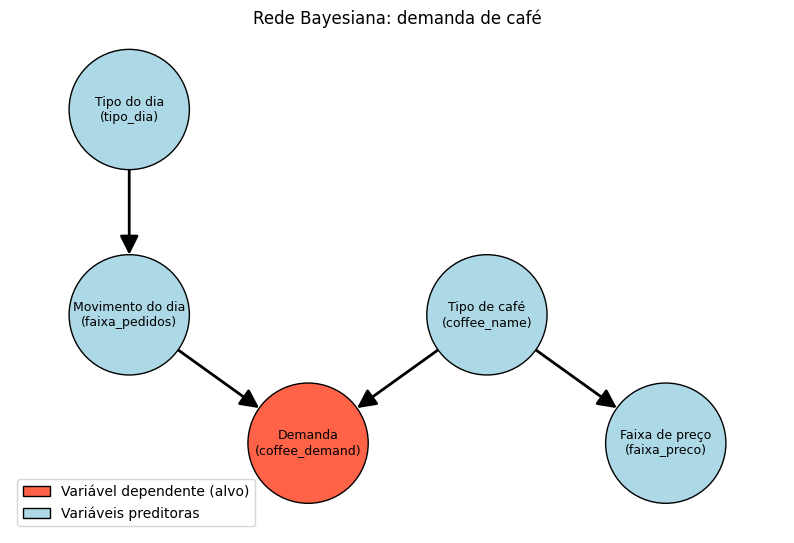

In [ ]:
import networkx as nx
from matplotlib.patches import Patch

rede = nx.DiGraph()
rede.add_edges_from([
    ('tipo_dia',      'faixa_pedidos'),   # o tipo do dia influencia o movimento do dia
    ('faixa_pedidos', 'coffee_demand'),   # o movimento do dia influencia a demanda do café
    ('coffee_name',   'coffee_demand'),   # o tipo de café influencia a demanda
    ('coffee_name',   'faixa_preco'),     # o tipo de café determina a faixa de preço
])

nomes = {
    'tipo_dia':      'Tipo do dia\n(tipo_dia)',
    'faixa_pedidos': 'Movimento do dia\n(faixa_pedidos)',
    'coffee_name':   'Tipo de café\n(coffee_name)',
    'faixa_preco':   'Faixa de preço\n(faixa_preco)',
    'coffee_demand': 'Demanda\n(coffee_demand)',
}

posicao = {
    'tipo_dia':      (0, 2.6),
    'faixa_pedidos': (0, 1),
    'coffee_name':   (3, 1),
    'coffee_demand': (1.5, 0),
    'faixa_preco':   (4.5, 0),
}

cores = ['tomato' if no == 'coffee_demand' else 'lightblue' for no in rede.nodes]

plt.figure(figsize=(10, 6.5))
nx.draw_networkx_nodes(rede, posicao, node_color=cores, node_size=7500, edgecolors='black')
nx.draw_networkx_labels(rede, posicao, labels=nomes, font_size=9)
nx.draw_networkx_edges(rede, posicao, arrows=True, arrowsize=28, node_size=7500, width=2)

plt.legend(handles=[Patch(facecolor='tomato', edgecolor='black', label='Variável dependente (alvo)'),
                    Patch(facecolor='lightblue', edgecolor='black', label='Variáveis preditoras')],
           loc='lower left')
plt.title('Rede Bayesiana: demanda de café')
plt.xlim(-1, 5.5)
plt.ylim(-0.7, 3.2)
plt.axis('off')

plt.savefig('rede_bayesiana.png', dpi=150, bbox_inches='tight')
plt.show()

### Por que cada arco existe

| Arco | Justificativa | Base |
|---|---|---|
| `coffee_name` → `faixa_preco` | O preço é definido pelo tipo de café (tabela de preços da máquina). | Análise descritiva: o preço médio varia de 21,00 (*Espresso*) a cerca de 36 (*Cappuccino*, *Hot Chocolate*), e dentro de cada café o preço varia pouco (CV de 3,7% a 9,9%). |
| `coffee_name` → `coffee_demand` | Cafés diferentes têm níveis de demanda muito diferentes. | Análise descritiva: o *Espresso* fica em demanda baixa em 86,6% das vendas, enquanto o *Americano with Milk* fica em demanda alta em 62,0%. |
| `faixa_pedidos` → `coffee_demand` | O movimento geral do dia pode mudar o perfil de demanda dos cafés. | Hipótese a verificar. |
| `tipo_dia` → `faixa_pedidos` | Dias úteis e fins de semana podem ter movimentos diferentes. | Hipótese a verificar. |


### Verificação rápida dos arcos



In [ ]:
# tipo_dia -> faixa_pedidos
display(pd.crosstab(dados_modelo['tipo_dia'], dados_modelo['faixa_pedidos'], normalize='index').round(3))

# faixa_pedidos -> coffee_demand
display(pd.crosstab(dados_modelo['faixa_pedidos'], dados_modelo['coffee_demand'], normalize='index').round(3))

# coffee_name -> faixa_preco
display(pd.crosstab(dados_modelo['coffee_name'], dados_modelo['faixa_preco'], normalize='index').round(3))

faixa_pedidos,baixo,medio,alto
tipo_dia,,,
dia_util,0.24,0.49,0.269
fim_de_semana,0.40,0.51,0.091


coffee_demand,low,medium,high
faixa_pedidos,,,
baixo,0.377,0.000,0.623
medio,0.485,0.067,0.448
alto,0.492,0.097,0.411


faixa_preco,baixo,medio,alto
coffee_name,,,
Americano,0.884,0.116,0.000
Americano with Milk,0.269,0.731,0.000
Cappuccino,0.000,0.192,0.808
Cocoa,0.000,0.111,0.889
Cortado,0.846,0.154,0.000
Espresso,1.000,0.000,0.000
Hot Chocolate,0.000,0.092,0.908
Latte,0.000,0.248,0.752


**Interpretação.** A terceira tabela deve mostrar que a faixa de preço é quase determinada pelo tipo de café: *Espresso*, *Cortado* e *Americano* concentram-se na faixa "baixo", o *Americano with Milk* na faixa "médio" e os demais cafés na faixa "alto", o que sustenta o arco `coffee_name` → `faixa_preco`.